# 03 学習済みCNN：conv2のTT-rank sweep

02では、rankを打ち切らないexact TT-Convへ`conv2`を置換し、学習済みCNN全体の推論がvalidation 5,000件で維持されることを確認しました。

03ではtensorizationを固定し、**requested rank upper boundだけを変えたとき、どこまでparameter数を削減でき、どこでaccuracyやdenseモデルとのprediction agreementが回復するか**を調べます。

## 1. このNotebookで確認すること

固定するtensorizationは、02と同じ

$$
(m_1,m_2,m_3)=(4,4,4),
\qquad
(n_1,n_2,n_3)=(6,6,8)
$$

です。各requested rank upper boundについて、次の流れを確認します。

$$
\text{requested rank upper bound}
\rightarrow\text{actual TT-ranks}
\rightarrow\text{weight error}
\rightarrow\text{conv2 output error}
\rightarrow\text{logits error}
\rightarrow\text{agreement / accuracy}.
$$

### このNotebookでは行わないこと

- tensorization比較
- fine-tuning、backward、optimizerの比較
- test setの再評価
- 複数層の同時圧縮
- latency、MACs、peak memoryの測定
- 速度・省メモリ性の主張

通常forwardではdense kernelを作りません。dense kernelの再構成は、weight errorと経路一致を確認する診断時だけ行います。

In [27]:
from __future__ import annotations
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import copy
import json
import math
import os
import sys
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        project_root = candidate
        break
else:
    raise RuntimeError("src/nn_compressionが見つかりません。")

from nn_compression.compression import (
    dense_to_tt_matrix_cores,
    tt_linear_forward,
    tt_matrix_num_parameters,
    tt_matrix_ranks,
    tt_matrix_to_dense,
)
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    split_fashion_mnist_dataset,
)
from nn_compression.metrics import agreement, count_parameters, logits_rmse
from nn_compression.models import FashionMNISTCNN
from nn_compression.selection import (
    extract_pareto_frontier,
    find_knee_point,
    get_endpoints,
    line_equation,
)
from nn_compression.training import evaluate
from nn_compression.utils import set_seed

SEED = 0
DEVICE = torch.device("cpu")
DTYPE = torch.float32
VALIDATION_BATCH_SIZE = 256

OUT_MODES = (4, 4, 4)
IN_MODES = (6, 6, 8)
RANK_CANDIDATES = [1, 2, 4, 8, 12, 16, 20, 24, 28, 29, 32]
SPLIT_LENGTHS = (50_000, 5_000, 5_000)
SAVE_RESULTS = True

DIRECT_PATH_ATOL = 1e-4
DIRECT_PATH_RTOL = 1e-4
EXACT_CONV2_RMSE_TOLERANCE = 1e-5
EXACT_LOGITS_RMSE_TOLERANCE = 1e-5
EXACT_MAX_ABS_LOGITS_DIFFERENCE_TOLERANCE = 1e-4
KNEE_DISTANCE_TOLERANCE = 1e-9

set_seed(SEED)
print("project root:", project_root)
print("device / dtype:", DEVICE, DTYPE)
print("requested rank upper bounds:", RANK_CANDIDATES)

project root: D:\dev\nn-compression-svd-dmrg
device / dtype: cpu torch.float32
requested rank upper bounds: [1, 2, 4, 8, 12, 16, 20, 24, 28, 29, 32]


## 2. baseline checkpointとデータの位置づけ

このbaselineは、Fashion-MNISTの55,000件で学習され、残り5,000件のvalidation lossでcheckpointが選択されています。したがって、03で使用するrank-selection validationは、baselineから独立した性能評価用データではなく、**baselineのcheckpoint選択にも使用した開発用データ**です。

今後のfine-tuning用に60,000件を50,000／5,000／5,000へ再構成しますが、中央の5,000件もbaseline学習時には55,000件の一部として使用済みです。将来は「baseline学習から独立したvalidation」ではなく、「fine-tuning時の監視用データ」として扱います。

02では分割indexを保存していないため、03では02と同じ55,000／5,000の分割手順を再現し、その末尾5,000件とrank-selection用5,000件のindexが一致することを確認します。さらに、3分割が非重複で合計60,000件になることを確認し、03で実際に使ったindexを保存します。

公式test setは取得しますが、このNotebookではloaderを作らず、再評価しません。baseline checkpointに既存のtest結果が含まれていても、rank選択には使いません。

In [28]:
checkpoint_path = (
    project_root
    / "models"
    / "10_svd"
    / "30_fashion_mnist_cnn"
    / "01_cnn_baseline"
    / "fashion_mnist_cnn_baseline.pt"
)
data_dir = project_root / "data"
results_dir = (
    project_root
    / "results"
    / "30_tt_mps"
    / "20_fashion_mnist_cnn"
    / "03_pretrained_cnn_conv2_tt_rank_sweep"
)

if not checkpoint_path.is_file():
    raise FileNotFoundError(f"baseline checkpointが見つかりません: {checkpoint_path}")

checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
if "model_state_dict" not in checkpoint:
    raise KeyError("checkpointにmodel_state_dictがありません。")

dense_model = FashionMNISTCNN().to(device=DEVICE, dtype=DTYPE)
dense_model.load_state_dict(checkpoint["model_state_dict"])
dense_model.eval()

dense_state_before = {
    name: value.detach().clone()
    for name, value in dense_model.state_dict().items()
}

full_train_dataset, test_dataset = get_fashion_mnist_datasets(
    data_dir, download=True
)

# 02の55,000／5,000分割手順を再現する。
_, validation_02_reproduced = split_fashion_mnist_dataset(
    full_train_dataset, (55_000, 5_000), seed=SEED
)

# 03以降で役割を分離するための50,000／5,000／5,000分割。
train_dataset, finetuning_monitor_dataset, rank_validation_dataset = (
    split_fashion_mnist_dataset(
        full_train_dataset, SPLIT_LENGTHS, seed=SEED
    )
)

train_indices = list(train_dataset.indices)
monitor_indices = list(finetuning_monitor_dataset.indices)
rank_validation_indices = list(rank_validation_dataset.indices)
validation_02_indices = list(validation_02_reproduced.indices)

assert rank_validation_indices == validation_02_indices
assert set(train_indices).isdisjoint(monitor_indices)
assert set(train_indices).isdisjoint(rank_validation_indices)
assert set(monitor_indices).isdisjoint(rank_validation_indices)
assert len(set(train_indices + monitor_indices + rank_validation_indices)) == 60_000
assert len(test_dataset) == 10_000

rank_validation_loader = DataLoader(
    rank_validation_dataset,
    batch_size=VALIDATION_BATCH_SIZE,
    shuffle=False,
)

dense_validation_loss, dense_validation_accuracy = evaluate(
    dense_model, rank_validation_loader, nn.CrossEntropyLoss(), DEVICE
)
dense_model_parameters = count_parameters(dense_model)

assert dense_model_parameters == 421_642
assert abs(dense_validation_accuracy - 0.9194) <= 1 / len(rank_validation_dataset)

print("checkpoint best epoch:", checkpoint.get("best_epoch"))
print("checkpoint selection validation loss:", checkpoint.get("best_validation_loss"))
print("rank-selection validation size:", len(rank_validation_dataset))
print("dense validation accuracy:", dense_validation_accuracy)
print("test size (not evaluated in 03):", len(test_dataset))

checkpoint best epoch: 10
checkpoint selection validation loss: 0.22325173783302307
rank-selection validation size: 5000
dense validation accuracy: 0.9194
test size (not evaluated in 03): 10000


### 02との評価batch sizeの違い

02はVALIDATION_BATCH_SIZE = 32でしたが、03は11個のrank候補を複数指標で評価する実行時間を抑えるため、256へ変更します。使用するsample、sample順、前処理、モデル、dtype、deviceは02と同じです。速度比較は行わないため、batch size 256の実行時間を性能結果として扱いません。

rank 32のcontrolは、02の表示値との完全な文字列一致ではなく、conv2 RMSE、logits RMSE、最大logits差の事前許容基準と、prediction agreement 1.0で判定します。同じ5,000件で全予測classが一致するため、validation accuracyもdenseモデルとの完全一致を要求します。

baselineの正解数は4,597 / 5,000です。割合の丸め値だけでなく、正解件数も完成コードで確認します。

In [29]:
dense_validation_correct_count = round(
    dense_validation_accuracy * len(rank_validation_dataset)
)
assert VALIDATION_BATCH_SIZE == 256
assert dense_validation_correct_count == 4_597
print(
    "dense validation correct count:",
    f"{dense_validation_correct_count} / {len(rank_validation_dataset)}",
)

dense validation correct count: 4597 / 5000


## 3. rank候補と圧縮境界

今回の3-core TT-matrixで、内部rankを$r_1,r_2$とすると、TT coresのparameter数は

$$
P_{\mathrm{cores}}
=24r_1+24r_1r_2+32r_2
$$

です。requested rankは$r_1,r_2$に共通の上限を与えますが、actual ranksが上限と同じになるとは限りません。必ず分解後のactual ranksを記録します。

rank 29は、想定actual ranksが$(1,24,29,1)$の場合に、dense weightの18,432要素より少ない18,208要素となる圧縮境界付近の候補です。rank 30、31は省略し、rank 32を02のexact controlとして使います。

これは内部rankペア全体の探索ではなく、**このtensorizationに共通rank上限を適用した範囲のsweep**です。

In [30]:
dense_conv2 = dense_model.conv2
assert tuple(dense_conv2.weight.shape) == (64, 32, 3, 3)
assert dense_conv2.groups == 1
assert dense_conv2.padding_mode == "zeros"

dense_conv2_weight_matrix = dense_conv2.weight.detach().reshape(64, 288)
dense_conv2_weight_parameters = dense_conv2_weight_matrix.numel()

exact_control_cores = dense_to_tt_matrix_cores(
    dense_conv2_weight_matrix,
    OUT_MODES,
    IN_MODES,
    max_rank=32,
)
exact_control_ranks = tt_matrix_ranks(exact_control_cores)
exact_control_core_parameters = tt_matrix_num_parameters(exact_control_cores)

assert exact_control_ranks == (1, 24, 32, 1)
assert dense_conv2_weight_parameters == 18_432
assert exact_control_core_parameters == 20_032

print("dense conv2 weight parameters:", dense_conv2_weight_parameters)
print("rank 32 actual ranks:", exact_control_ranks)
print("rank 32 TT core parameters:", exact_control_core_parameters)

dense conv2 weight parameters: 18432
rank 32 actual ranks: (1, 24, 32, 1)
rank 32 TT core parameters: 20032


## 4. 02で完成した`TTConv2d`を再利用する

以下は02で実装・検証した内容です。03の学習対象はrank sweepなので、`TTConv2d`自体はTODOに戻しません。

- TT coresは`nn.ParameterList`として保持する。
- biasは`nn.Parameter`として保持する。
- denseな`weight` parameterは保持しない。
- `F.unfold`で得たpatchへ`tt_linear_forward`を適用する。
- 対応範囲は`groups=1`、zero paddingである。

In [31]:
def _as_pair(
    value: int | tuple[int, int],
    name: str,
    minimum: int,
) -> tuple[int, int]:
    """Conv2d設定を2整数のtupleへ正規化する。"""
    if isinstance(value, int) and not isinstance(value, bool):
        value = (value, value)
    if not isinstance(value, tuple) or len(value) != 2:
        raise TypeError(f"{name} must be an int or a tuple of two ints.")
    if not all(isinstance(v, int) and not isinstance(v, bool) for v in value):
        raise TypeError(f"{name} must contain integers.")
    if any(v < minimum for v in value):
        raise ValueError(f"Each value in {name} must be >= {minimum}.")
    return value


def _validate_ttconv_inputs(
    cores: list[torch.Tensor] | tuple[torch.Tensor, ...],
    bias: torch.Tensor | None,
    in_channels: int,
    out_channels: int,
    groups: int,
    padding_mode: str,
    kernel_size: tuple[int, int],
    out_modes: tuple[int, ...],
    in_modes: tuple[int, ...],
) -> None:
    """03で使用するTTConv2dの構造条件を検証する。"""
    if groups != 1:
        raise NotImplementedError("Only groups=1 is supported.")
    if padding_mode != "zeros":
        raise NotImplementedError("Only zero padding is supported.")
    if not (len(cores) == len(out_modes) == len(in_modes)):
        raise ValueError("The numbers of cores and modes must match.")
    if len(cores) == 0:
        raise ValueError("cores must not be empty.")
    if math.prod(out_modes) != out_channels:
        raise ValueError("The product of out_modes must equal out_channels.")
    if math.prod(in_modes) != in_channels * math.prod(kernel_size):
        raise ValueError(
            "The product of in_modes must equal the receptive-field width."
        )
    for index, core in enumerate(cores):
        expected_modes = (out_modes[index], in_modes[index])
        if core.ndim != 4 or tuple(core.shape[1:3]) != expected_modes:
            raise ValueError(f"core {index} has incompatible physical modes.")
        if core.dtype != cores[0].dtype or core.device != cores[0].device:
            raise ValueError("All cores must have the same dtype and device.")
    if cores[0].shape[0] != 1 or cores[-1].shape[-1] != 1:
        raise ValueError("Boundary ranks must be 1.")
    for left, right in zip(cores[:-1], cores[1:]):
        if left.shape[-1] != right.shape[0]:
            raise ValueError("Adjacent bond dimensions must match.")
    if bias is not None:
        if tuple(bias.shape) != (out_channels,):
            raise ValueError("bias must have shape (out_channels,).")
        if bias.dtype != cores[0].dtype or bias.device != cores[0].device:
            raise ValueError("bias and cores must have the same dtype and device.")


class TTConv2d(nn.Module):
    """TT-matrix coresをparameterとして保持する2次元畳み込み層。"""

    def __init__(
        self,
        cores: list[torch.Tensor],
        bias: torch.Tensor | None,
        in_channels: int,
        out_channels: int,
        kernel_size: int | tuple[int, int],
        stride: int | tuple[int, int],
        padding: int | tuple[int, int],
        dilation: int | tuple[int, int],
        groups: int,
        padding_mode: str,
        out_modes: tuple[int, ...],
        in_modes: tuple[int, ...],
    ) -> None:
        super().__init__()
        kernel_size = _as_pair(kernel_size, "kernel_size", minimum=1)
        stride = _as_pair(stride, "stride", minimum=1)
        padding = _as_pair(padding, "padding", minimum=0)
        dilation = _as_pair(dilation, "dilation", minimum=1)
        _validate_ttconv_inputs(
            cores, bias, in_channels, out_channels, groups, padding_mode,
            kernel_size, tuple(out_modes), tuple(in_modes)
        )

        self.cores = nn.ParameterList([
            nn.Parameter(core.detach().clone()) for core in cores
        ])
        if bias is None:
            self.register_parameter("bias", None)
        else:
            self.bias = nn.Parameter(bias.detach().clone())

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding
        self.dilation = dilation
        self.groups = groups
        self.padding_mode = padding_mode
        self.out_modes = tuple(out_modes)
        self.in_modes = tuple(in_modes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.ndim != 4 or x.shape[1] != self.in_channels:
            raise ValueError(
                "x must have shape (batch, in_channels, height, width)."
            )
        if x.dtype != self.cores[0].dtype or x.device != self.cores[0].device:
            raise ValueError("x and TT cores must have the same dtype and device.")

        batch_size, _, input_height, input_width = x.shape
        output_height = (
            input_height + 2 * self.padding[0]
            - self.dilation[0] * (self.kernel_size[0] - 1) - 1
        ) // self.stride[0] + 1
        output_width = (
            input_width + 2 * self.padding[1]
            - self.dilation[1] * (self.kernel_size[1] - 1) - 1
        ) // self.stride[1] + 1
        if output_height <= 0 or output_width <= 0:
            raise ValueError("The convolution settings produce an invalid output size.")

        unfolded = F.unfold(
            x,
            kernel_size=self.kernel_size,
            dilation=self.dilation,
            padding=self.padding,
            stride=self.stride,
        )
        output_positions = output_height * output_width
        patch_width = self.in_channels * math.prod(self.kernel_size)
        patch_matrix = unfolded.permute(0, 2, 1).reshape(
            batch_size * output_positions, patch_width
        )
        patch_output = tt_linear_forward(
            patch_matrix,
            list(self.cores),
            self.out_modes,
            self.in_modes,
            bias=self.bias,
        )
        return patch_output.reshape(
            batch_size, output_height, output_width, self.out_channels
        ).permute(0, 3, 1, 2)

## 5. 完成コード：各rankの診断と評価

TODOがTT固有のrank sweepへ集中するよう、全validationの集計処理は完成コードにします。

### `evaluate_rank_candidate`の入力

- `requested_rank_upper_bound: int`：2本の内部bondに共通して与えたrank上限。
- `dense_model: nn.Module`：比較基準の学習済みCNN。
- `tt_model: nn.Module`：`conv2`だけをrank制限TT-Convへ置換した独立モデル。
- `cores: list[torch.Tensor]`：同じ元dense weightからTT-SVDしたcores。
- `data_loader: DataLoader`：順序を固定したrank-selection validation loader。
- `direct_check_images: torch.Tensor`：direct経路と再構成kernel経路を照合する少数画像。

### 戻り値

1 rank分の`dict[str, object]`を返します。主な列の意味は次です。

- `model_parameters`：TT置換後モデルが保持する全parameter要素数。
- `conv2_weight_to_core_compression_ratio`：$18{,}432/P_{\mathrm{cores}}$。1より大きいとweight対coresで削減。
- `model_compression_ratio`：$421{,}642/P_{\mathrm{model}}$。1より大きいとモデル全体で削減。
- `signed_accuracy_drop`：`dense_validation_accuracy - validation_accuracy`。割合で保存し、負値も保持。
- `direct_vs_reconstructed_max_abs_difference`：同じrank制限coresを使うTT direct forwardと診断用dense kernel経路の最大差。元dense kernelとの比較ではありません。

`validation_error = 1 - validation_accuracy`は保存指標ではなく、後のPareto処理で作ります。

In [32]:
def collect_conv2_and_logits_diagnostics(
    dense_model: nn.Module,
    tt_model: nn.Module,
    data_loader: DataLoader,
    device: torch.device,
) -> dict[str, float]:
    """validation全体のconv2 RMSEと最大logits絶対差を返す。"""
    dense_model.eval()
    tt_model.eval()
    conv2_squared_error_sum = 0.0
    conv2_element_count = 0
    max_abs_logits_difference = 0.0

    with torch.inference_mode():
        for images, _ in data_loader:
            images = images.to(device=device, dtype=DTYPE)
            shared_conv2_input = dense_model.pool1(
                dense_model.relu1(dense_model.conv1(images))
            )
            dense_conv2_output = dense_model.conv2(shared_conv2_input)
            tt_conv2_output = tt_model.conv2(shared_conv2_input)
            difference = dense_conv2_output - tt_conv2_output
            conv2_squared_error_sum += difference.double().square().sum().item()
            conv2_element_count += difference.numel()

            logits_difference = dense_model(images) - tt_model(images)
            max_abs_logits_difference = max(
                max_abs_logits_difference,
                logits_difference.abs().max().item(),
            )

    if conv2_element_count == 0:
        raise ValueError("空のDataLoaderでは診断できません。")
    return {
        "conv2_output_rmse": (
            conv2_squared_error_sum / conv2_element_count
        ) ** 0.5,
        "max_abs_logits_difference": max_abs_logits_difference,
    }


def direct_vs_reconstructed_conv_max_abs_difference(
    dense_model: nn.Module,
    tt_model: nn.Module,
    cores: list[torch.Tensor],
    images: torch.Tensor,
) -> float:
    """同じTT coresを使うdirect経路と診断用dense経路の最大差を返す。"""
    tt_layer = tt_model.conv2
    reconstructed_matrix = tt_matrix_to_dense(cores, OUT_MODES, IN_MODES)
    reconstructed_kernel = reconstructed_matrix.reshape_as(dense_model.conv2.weight)

    with torch.inference_mode():
        images = images.to(device=DEVICE, dtype=DTYPE)
        shared_input = dense_model.pool1(
            dense_model.relu1(dense_model.conv1(images))
        )
        direct_output = tt_layer(shared_input)
        reconstructed_output = F.conv2d(
            shared_input,
            reconstructed_kernel,
            bias=tt_layer.bias,
            stride=tt_layer.stride,
            padding=tt_layer.padding,
            dilation=tt_layer.dilation,
            groups=tt_layer.groups,
        )

    torch.testing.assert_close(
        direct_output, reconstructed_output,
        atol=DIRECT_PATH_ATOL, rtol=DIRECT_PATH_RTOL
    )
    return (direct_output - reconstructed_output).abs().max().item()


def evaluate_rank_candidate(
    requested_rank_upper_bound: int,
    dense_model: nn.Module,
    tt_model: nn.Module,
    cores: list[torch.Tensor],
    data_loader: DataLoader,
    direct_check_images: torch.Tensor,
) -> dict[str, object]:
    """1つのrank制限TTモデルを診断・評価し、保存用recordを返す。"""
    actual_ranks = tt_matrix_ranks(cores)
    tt_core_parameters = tt_matrix_num_parameters(cores)
    model_parameters = count_parameters(tt_model)

    reconstructed_weight = tt_matrix_to_dense(cores, OUT_MODES, IN_MODES)
    weight_difference = dense_conv2_weight_matrix - reconstructed_weight
    relative_weight_error = (
        torch.linalg.vector_norm(weight_difference)
        / torch.linalg.vector_norm(dense_conv2_weight_matrix)
    ).item()

    _, validation_accuracy = evaluate(
        tt_model, data_loader, nn.CrossEntropyLoss(), DEVICE
    )
    prediction_agreement = agreement(
        dense_model, tt_model, data_loader, DEVICE
    )
    model_logits_rmse = logits_rmse(
        dense_model, tt_model, data_loader, DEVICE
    )
    diagnostics = collect_conv2_and_logits_diagnostics(
        dense_model, tt_model, data_loader, DEVICE
    )
    direct_path_difference = direct_vs_reconstructed_conv_max_abs_difference(
        dense_model, tt_model, cores, direct_check_images
    )

    return {
        "requested_rank_upper_bound": requested_rank_upper_bound,
        "actual_ranks": actual_ranks,
        "tt_core_parameters": tt_core_parameters,
        "model_parameters": model_parameters,
        "conv2_weight_to_core_compression_ratio": (
            dense_conv2_weight_parameters / tt_core_parameters
        ),
        "model_compression_ratio": (
            dense_model_parameters / model_parameters
        ),
        "weight_relative_frobenius_error": relative_weight_error,
        "conv2_output_rmse": diagnostics["conv2_output_rmse"],
        "logits_rmse": model_logits_rmse,
        "max_abs_logits_difference": diagnostics["max_abs_logits_difference"],
        "prediction_agreement": prediction_agreement,
        "validation_accuracy": validation_accuracy,
        "signed_accuracy_drop": dense_validation_accuracy - validation_accuracy,
        "direct_vs_reconstructed_max_abs_difference": direct_path_difference,
        "is_exact_control": requested_rank_upper_bound == 32,
    }


direct_check_images, _ = next(iter(rank_validation_loader))
direct_check_images = direct_check_images[:2].detach().clone()
print("completed evaluation helpers: OK")

completed evaluation helpers: OK


### 各rank候補で固定する比較条件

evaluate_rank_candidateを呼ぶ前に、完成コードで次を確認します。

- tt_modelはdense_modelとは別のモデルで、conv2だけがTTConv2dへ置換されている。
- conv2以外のparameter・bufferはdenseモデルと一致する。
- biasと畳み込み設定は元のconv2と一致する。
- coresとbiasが学習可能parameterとして、想定dtype・deviceで登録されている。
- TT層はdenseなweightを保持しない。
- 診断用引数coresと、実際の推論に使うtt_model.conv2.coresはshape・dtype・device・値が一致する。同じオブジェクトである必要はない。
- biasを維持したままweightだけをcoresへ置換するため、parameter数は

$$
P_{\mathrm{model}}
=421{,}642-18{,}432+P_{\mathrm{cores}}
$$

を満たす。

これにより、TODOで別のCNNを新規初期化した場合や、記録対象とは異なるcoresをモデルへ渡した場合を、各rankの評価前に検出します。

In [33]:
def validate_rank_candidate_structure(
    dense_model: nn.Module,
    tt_model: nn.Module,
    cores: list[torch.Tensor],
) -> None:
    """rank候補がdenseモデルとの差をconv2置換だけに限定しているか検証する。"""
    if tt_model is dense_model:
        raise ValueError("tt_model must be independent from dense_model.")
    if not isinstance(tt_model.conv2, TTConv2d):
        raise TypeError("tt_model.conv2 must be TTConv2d.")

    tt_layer = tt_model.conv2
    dense_layer = dense_model.conv2
    if hasattr(tt_layer, "weight"):
        raise ValueError("TTConv2d must not hold a dense weight parameter.")
    if not isinstance(tt_layer.cores, nn.ParameterList):
        raise TypeError("TT cores must be registered in nn.ParameterList.")
    if len(tt_layer.cores) != len(cores):
        raise ValueError("The diagnostic cores and registered cores must match in length.")

    for index, (source_core, registered_core) in enumerate(
        zip(cores, tt_layer.cores)
    ):
        if not isinstance(registered_core, nn.Parameter):
            raise TypeError(f"Registered core {index} must be nn.Parameter.")
        if not registered_core.requires_grad:
            raise ValueError(f"Registered core {index} must require gradients.")
        if registered_core.shape != source_core.shape:
            raise ValueError(f"Core {index} shape does not match the diagnostic core.")
        if (
            registered_core.dtype != source_core.dtype
            or registered_core.device != source_core.device
        ):
            raise ValueError(
                f"Core {index} dtype/device does not match the diagnostic core."
            )
        if registered_core.dtype != DTYPE or registered_core.device != DEVICE:
            raise ValueError(f"Registered core {index} has unexpected dtype/device.")
        torch.testing.assert_close(registered_core.detach(), source_core.detach())

    if dense_layer.bias is None:
        if tt_layer.bias is not None:
            raise ValueError("TT bias must remain None.")
    else:
        if not isinstance(tt_layer.bias, nn.Parameter):
            raise TypeError("TT bias must be registered as nn.Parameter.")
        if not tt_layer.bias.requires_grad:
            raise ValueError("TT bias must require gradients.")
        if tt_layer.bias is dense_layer.bias:
            raise ValueError("TT bias must not share the dense Parameter object.")
        if tt_layer.bias.dtype != DTYPE or tt_layer.bias.device != DEVICE:
            raise ValueError("TT bias has unexpected dtype/device.")
        torch.testing.assert_close(
            tt_layer.bias.detach(), dense_layer.bias.detach()
        )

    setting_names = (
        "in_channels", "out_channels", "kernel_size", "stride",
        "padding", "dilation", "groups", "padding_mode",
    )
    for name in setting_names:
        if getattr(tt_layer, name) != getattr(dense_layer, name):
            raise ValueError(f"conv2 setting {name!r} does not match.")
    if tt_layer.out_modes != OUT_MODES or tt_layer.in_modes != IN_MODES:
        raise ValueError("TTConv2d modes do not match the fixed tensorization.")

    registered_parameter_names = {
        name for name, _ in tt_layer.named_parameters()
    }
    expected_parameter_names = {
        *(f"cores.{index}" for index in range(len(cores))),
        "bias",
    }
    if registered_parameter_names != expected_parameter_names:
        raise ValueError(
            "TTConv2d must register only cores and bias as parameters."
        )

    dense_state = dense_model.state_dict()
    tt_state = tt_model.state_dict()
    for name, dense_value in dense_state.items():
        if name.startswith("conv2."):
            continue
        if name not in tt_state:
            raise KeyError(f"TT model is missing unchanged state {name!r}.")
        torch.testing.assert_close(tt_state[name], dense_value)

    tt_core_parameters = tt_matrix_num_parameters(cores)
    expected_model_parameters = (
        dense_model_parameters
        - dense_conv2_weight_parameters
        + tt_core_parameters
    )
    if count_parameters(tt_model) != expected_model_parameters:
        raise ValueError("TT model parameter count is inconsistent with core replacement.")


_evaluate_rank_candidate_metrics = evaluate_rank_candidate


def evaluate_rank_candidate(
    requested_rank_upper_bound: int,
    dense_model: nn.Module,
    tt_model: nn.Module,
    cores: list[torch.Tensor],
    data_loader: DataLoader,
    direct_check_images: torch.Tensor,
) -> dict[str, object]:
    """構造条件を検証してから、1つのrank候補の評価recordを返す。"""
    validate_rank_candidate_structure(dense_model, tt_model, cores)
    record = _evaluate_rank_candidate_metrics(
        requested_rank_upper_bound,
        dense_model,
        tt_model,
        cores,
        data_loader,
        direct_check_images,
    )
    expected_model_parameters = (
        dense_model_parameters
        - dense_conv2_weight_parameters
        + int(record["tt_core_parameters"])
    )
    if int(record["model_parameters"]) != expected_model_parameters:
        raise ValueError("Saved model parameter count is inconsistent.")
    return record

### direct経路一致の判定

TT direct forwardと、同じcoresから診断用に再構成したkernelによるConvの一致は、前の完成helper内のtorch.testing.assert_closeで判定します。atolとrtolを含むこの判定を合格条件とし、direct_vs_reconstructed_max_abs_differenceは大きさを確認する診断値としてのみ保存します。最大絶対差へ同じatolを再適用しません。

## 6. TODO 1：同じ元dense weightからrank sweepする

### このTODOでやりたいこと

`RANK_CANDIDATES`の各requested rank upper boundについて、同じ元の`dense_conv2_weight_matrix`からTT-SVDを行い、`conv2`だけをrank制限TT-Convへ置換した独立モデルを評価します。

### 入力変数と意味

- `RANK_CANDIDATES: list[int]`：2本の内部bondへ共通に与えるrank上限。
- `dense_conv2_weight_matrix: torch.Tensor`：すべてのrankで共通の分解元。shapeは`(64, 288)`。
- `dense_model: nn.Module`：変更してはいけない比較基準モデル。
- `dense_conv2: nn.Conv2d`：bias、stride、paddingなどを引き継ぐ置換元層。
- `OUT_MODES`、`IN_MODES`：02から固定したtensorization。
- `rank_validation_loader: DataLoader`：rank選択用5,000件を同じ順序で供給するloader。
- `direct_check_images: torch.Tensor`：経路一致を確認する先頭2件の画像。

### 作成する出力変数

- `rank_records: list[dict[str, object]]`：各rankの`evaluate_rank_candidate`戻り値を格納したlist。
- `df_rank_sweep: pd.DataFrame`：`rank_records`をrequested rank順に並べた表。1候補につき1行。

### 期待する状態

- 各rankは、前のrankの近似weightやexact coresの切り出しではなく、同じ元dense weightから分解される。
- 各TTモデルは独立しており、`dense_model`は変更されない。
- `requested_rank_upper_bound`と`actual_ranks`を別々に記録する。
- rank 32はexact controlとして、actual ranks `(1, 24, 32, 1)`を再現する。
- accuracyとagreementの単調性は仮定しない。
- 前のセルにある評価helperへモデルとcoresを渡し、集計処理自体は再実装しない。

### このTODOでは行わないこと

- tensorizationやrank候補の変更
- fine-tuningやbackward
- Pareto・knee選択
- test評価

具体的な関数呼び出し順や代入式は、ここでは示しません。

In [36]:
rank_records = []

for requested_rank in RANK_CANDIDATES:
    # 毎回、同じ元dense weightから分解する
    cores =  dense_to_tt_matrix_cores(
        dense_conv2_weight_matrix,
        OUT_MODES,
        IN_MODES,
         max_rank=requested_rank
    )
    # この段階だけの確認用表示
    print(
        "requested:", requested_rank,
        "actual:", tt_matrix_ranks(cores),
        "core parameters:", tt_matrix_num_parameters(cores),
    )
        # 元の学習済みモデルから、今回のrank用の独立コピーを作る
    tt_model = copy.deepcopy(dense_model)

    # 今回のrankで作ったcoresを使うTT層
    tt_conv2 = TTConv2d(
        cores=cores,
        bias=dense_conv2.bias,
        in_channels=dense_conv2.in_channels,
        out_channels=dense_conv2.out_channels,
        kernel_size=dense_conv2.kernel_size,
        stride=dense_conv2.stride,
        padding=dense_conv2.padding,
        dilation=dense_conv2.dilation,
        groups=dense_conv2.groups,
        padding_mode=dense_conv2.padding_mode,
        out_modes=OUT_MODES,
        in_modes=IN_MODES,
    )

    # コピーしたモデルのconv2だけを置き換える
    tt_model.conv2 = tt_conv2

    tt_model.eval()

        # ループ内：今回のrankのモデルを評価する
    record = evaluate_rank_candidate(
        requested_rank_upper_bound=requested_rank,
        dense_model=dense_model,
        tt_model=tt_model,
        cores=cores,
        data_loader=rank_validation_loader,
        direct_check_images=direct_check_images,
    )

    # ループ内：今回の評価結果をリストへ追加する
    rank_records.append(record)


# ループ外：全rankの結果を表にする
df_rank_sweep = pd.DataFrame(rank_records).sort_values(
    "requested_rank_upper_bound"
).reset_index(drop=True)

requested: 1 actual: (1, 1, 1, 1) core parameters: 80
requested: 2 actual: (1, 2, 2, 1) core parameters: 208
requested: 4 actual: (1, 4, 4, 1) core parameters: 608
requested: 8 actual: (1, 8, 8, 1) core parameters: 1984
requested: 12 actual: (1, 12, 12, 1) core parameters: 4128
requested: 16 actual: (1, 16, 16, 1) core parameters: 7040
requested: 20 actual: (1, 20, 20, 1) core parameters: 10720
requested: 24 actual: (1, 24, 24, 1) core parameters: 15168
requested: 28 actual: (1, 24, 28, 1) core parameters: 17600
requested: 29 actual: (1, 24, 29, 1) core parameters: 18208
requested: 32 actual: (1, 24, 32, 1) core parameters: 20032


In [37]:
required_todo_names = ("rank_records", "df_rank_sweep")
missing_todo_names = [
    name for name in required_todo_names if name not in globals()
]

if missing_todo_names:
    print("TODO 1未実装:", missing_todo_names)
else:
    expected_columns = {
        "requested_rank_upper_bound", "actual_ranks",
        "tt_core_parameters", "model_parameters",
        "conv2_weight_to_core_compression_ratio",
        "model_compression_ratio",
        "weight_relative_frobenius_error",
        "conv2_output_rmse", "logits_rmse",
        "max_abs_logits_difference", "prediction_agreement",
        "validation_accuracy", "signed_accuracy_drop",
        "direct_vs_reconstructed_max_abs_difference",
        "is_exact_control",
    }
    if not isinstance(rank_records, list):
        raise TypeError("rank_records must be a list.")
    if not isinstance(df_rank_sweep, pd.DataFrame):
        raise TypeError("df_rank_sweep must be a pandas DataFrame.")
    if not expected_columns.issubset(df_rank_sweep.columns):
        missing = expected_columns - set(df_rank_sweep.columns)
        raise KeyError(f"df_rank_sweepに必要な列がありません: {sorted(missing)}")

    df_rank_sweep = df_rank_sweep.sort_values(
        "requested_rank_upper_bound"
    ).reset_index(drop=True)
    assert len(rank_records) == len(RANK_CANDIDATES)
    assert df_rank_sweep["requested_rank_upper_bound"].tolist() == RANK_CANDIDATES
    assert df_rank_sweep["tt_core_parameters"].is_monotonic_increasing
    assert df_rank_sweep["model_parameters"].is_monotonic_increasing
    assert df_rank_sweep["validation_accuracy"].between(0.0, 1.0).all()
    assert df_rank_sweep["prediction_agreement"].between(0.0, 1.0).all()
    assert (df_rank_sweep["weight_relative_frobenius_error"] >= 0.0).all()
    assert (df_rank_sweep["conv2_output_rmse"] >= 0.0).all()
    assert (df_rank_sweep["logits_rmse"] >= 0.0).all()
    assert (df_rank_sweep["max_abs_logits_difference"] >= 0.0).all()
    # assert_closeを合格判定とし、最大絶対差は非負の診断値として保存する。
    assert (
        df_rank_sweep["direct_vs_reconstructed_max_abs_difference"] >= 0.0
    ).all()

    expected_drop = (
        dense_validation_accuracy - df_rank_sweep["validation_accuracy"]
    )
    np.testing.assert_allclose(
        df_rank_sweep["signed_accuracy_drop"], expected_drop
    )
    np.testing.assert_allclose(
        df_rank_sweep["conv2_weight_to_core_compression_ratio"],
        dense_conv2_weight_parameters / df_rank_sweep["tt_core_parameters"],
    )
    np.testing.assert_allclose(
        df_rank_sweep["model_compression_ratio"],
        dense_model_parameters / df_rank_sweep["model_parameters"],
    )

    exact_row = df_rank_sweep.loc[
        df_rank_sweep["requested_rank_upper_bound"] == 32
    ].iloc[0]
    assert tuple(exact_row["actual_ranks"]) == (1, 24, 32, 1)
    assert int(exact_row["tt_core_parameters"]) == 20_032
    assert int(exact_row["model_parameters"]) == 423_242
    assert exact_row["conv2_output_rmse"] <= EXACT_CONV2_RMSE_TOLERANCE
    assert exact_row["logits_rmse"] <= EXACT_LOGITS_RMSE_TOLERANCE
    assert (
        exact_row["max_abs_logits_difference"]
        <= EXACT_MAX_ABS_LOGITS_DIFFERENCE_TOLERANCE
    )
    assert float(exact_row["prediction_agreement"]) == 1.0
    assert float(exact_row["validation_accuracy"]) == dense_validation_accuracy

    dense_state_after = dense_model.state_dict()
    assert dense_state_after.keys() == dense_state_before.keys()
    for name, before_value in dense_state_before.items():
        torch.testing.assert_close(dense_state_after[name], before_value)

    display(df_rank_sweep)
    print("TODO 1 and exact-control checks: OK")

,requested_rank_upper_bound,actual_ranks,tt_core_parameters,model_parameters,conv2_weight_to_core_compression_ratio,model_compression_ratio,weight_relative_frobenius_error,conv2_output_rmse,logits_rmse,max_abs_logits_difference,prediction_agreement,validation_accuracy,signed_accuracy_drop,direct_vs_reconstructed_max_abs_difference,is_exact_control
0,1,"(1, 1, 1, 1)",80,403290,230.400000,1.045506,0.992476,4.823632e-01,6.609576,23.800186,0.1502,0.1484,0.7710,2.086163e-07,False
1,2,"(1, 2, 2, 1)",208,403418,88.615385,1.045174,0.979769,4.848417e-01,6.554081,23.685360,0.2110,0.2076,0.7118,2.980232e-07,False
2,4,"(1, 4, 4, 1)",608,403818,30.315789,1.044139,0.950630,4.719790e-01,6.099427,23.876907,0.3362,0.3260,0.5934,5.364418e-07,False
3,8,"(1, 8, 8, 1)",1984,405194,9.290323,1.040593,0.871734,4.217781e-01,5.441864,20.598183,0.3830,0.3708,0.5486,9.536743e-07,False
4,12,"(1, 12, 12, 1)",4128,407338,4.465116,1.035116,0.779331,3.352463e-01,4.575248,16.737247,0.7074,0.6910,0.2284,1.192093e-06,False
5,16,"(1, 16, 16, 1)",7040,410250,2.618182,1.027768,0.665489,2.544528e-01,3.259895,12.020472,0.8508,0.8198,0.0996,1.668930e-06,False
6,20,"(1, 20, 20, 1)",10720,413930,1.719403,1.018631,0.525631,1.693108e-01,1.965577,7.514039,0.9428,0.8970,0.0224,1.907349e-06,False
7,24,"(1, 24, 24, 1)",15168,418378,1.215190,1.007802,0.354743,8.167651e-02,0.725746,2.825630,0.9814,0.9192,0.0002,1.907349e-06,False
8,28,"(1, 24, 28, 1)",17600,420810,1.047273,1.001977,0.232958,4.217407e-02,0.319868,1.552500,0.9898,0.9204,-0.0010,2.384186e-06,False
9,29,"(1, 24, 29, 1)",18208,421418,1.012302,1.000532,0.199125,3.477794e-02,0.244143,1.201580,0.9902,0.9206,-0.0012,2.384186e-06,False


TODO 1 and exact-control checks: OK


## 7. 完成コード：Pareto frontierと曖昧さを許すknee候補

圧縮候補は、

$$
P_{\mathrm{cores}} < 18{,}432
$$

を満たす行だけです。横軸をTT core parameter数、縦軸を

$$
\text{validation error}=1-\text{validation accuracy}
$$

として、両方を最小化するPareto frontierを求めます。今回は他の層が固定なので、core parameter数とモデル全体parameter数のどちらを使っても支配関係は同じです。

frontierを0〜1へ正規化した後、既存APIで端点間の直線から最も離れた点を調べます。ただし、次の場合はkneeを確定しません。

- frontierが2点以下
- 正規化する軸の幅が0
- 最大距離がほぼ0、または最大距離が同率
- 選ばれた点が最小化問題で望ましい側へ曲がっていない
- 選ばれた点が内部点でない

曖昧な場合に別規則で候補を補いません。結果には、kneeを決められたか、理由、選択された役割を保存します。kneeは唯一の最適解ではなく、04へ渡す探索予算候補です。

In [38]:
def select_rank_budget_candidates(
    rank_sweep: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame, dict[str, object]]:
    """圧縮候補のPareto frontierと、定義できる場合だけknee近傍を返す。"""
    compressed = rank_sweep.loc[
        rank_sweep["tt_core_parameters"] < dense_conv2_weight_parameters
    ].copy()
    compressed = compressed.sort_values(
        ["tt_core_parameters", "validation_accuracy",
         "requested_rank_upper_bound"],
        ascending=[True, False, True],
    )
    # 同一目的値では、最小requested上限を代表として残す。
    compressed = compressed.drop_duplicates(
        subset=["tt_core_parameters", "validation_accuracy"],
        keep="first",
    ).reset_index(drop=True)
    compressed["validation_error"] = 1.0 - compressed["validation_accuracy"]

    if compressed.empty:
        empty = compressed.copy()
        empty["selection_role"] = pd.Series(dtype="object")
        return empty, empty, {
            "knee_defined": False,
            "reason": "圧縮候補がない",
            "knee_distance": None,
            "selection_method": "normalized Pareto chord distance",
        }

    pareto = extract_pareto_frontier(
        compressed,
        x_column="tt_core_parameters",
        y_column="validation_error",
    ).sort_values("tt_core_parameters").reset_index(drop=True)
    empty_selected = pareto.iloc[0:0].copy()
    empty_selected["selection_role"] = pd.Series(dtype="object")

    status: dict[str, object] = {
        "knee_defined": False,
        "reason": None,
        "knee_distance": None,
        "selection_method": "normalized Pareto chord distance",
        "pareto_point_count": len(pareto),
    }

    if len(pareto) <= 2:
        status["reason"] = "Pareto点が2点以下で内部kneeを定義できない"
        return pareto, empty_selected, status

    x_values = pareto["tt_core_parameters"].to_numpy(dtype=float)
    y_values = pareto["validation_error"].to_numpy(dtype=float)
    x_span = float(x_values.max() - x_values.min())
    y_span = float(y_values.max() - y_values.min())
    if x_span == 0.0 or y_span == 0.0:
        status["reason"] = "Pareto軸の幅が0で正規化できない"
        return pareto, empty_selected, status

    normalized = pareto.copy()
    normalized["normalized_parameters"] = (x_values - x_values.min()) / x_span
    normalized["normalized_validation_error"] = (
        y_values - y_values.min()
    ) / y_span

    p0, p1 = get_endpoints(
        normalized,
        column="normalized_parameters",
        x="normalized_parameters",
        y="normalized_validation_error",
    )
    slope, intercept = line_equation(p0, p1)
    knee_point, knee_distance = find_knee_point(
        normalized, slope, intercept,
        x="normalized_parameters",
        y="normalized_validation_error",
    )
    status["knee_distance"] = knee_distance

    nx = normalized["normalized_parameters"].to_numpy(dtype=float)
    ny = normalized["normalized_validation_error"].to_numpy(dtype=float)
    distances = np.abs(slope * nx - ny + intercept) / math.sqrt(slope**2 + 1.0)
    max_distance = float(distances.max())
    tied = np.isclose(
        distances, max_distance, rtol=1e-9, atol=KNEE_DISTANCE_TOLERANCE
    )

    if max_distance <= KNEE_DISTANCE_TOLERANCE:
        status["reason"] = "Pareto点がほぼ直線上でkneeが明確でない"
        return pareto, empty_selected, status
    if int(tied.sum()) != 1:
        status["reason"] = "最大距離が同率でkneeが一意でない"
        return pareto, empty_selected, status

    knee_index = int(np.flatnonzero(tied)[0])
    if knee_index == 0 or knee_index == len(normalized) - 1:
        status["reason"] = "選択点がfrontierの内部点でない"
        return pareto, empty_selected, status

    # 最小化問題では、端点間の線より原点側へ曲がる点を採用する。
    preferred_side = slope * nx[knee_index] - ny[knee_index] + intercept
    if preferred_side <= KNEE_DISTANCE_TOLERANCE:
        status["reason"] = "最大距離点が最小化問題で望ましい側にない"
        return pareto, empty_selected, status

    np.testing.assert_allclose(
        np.array(knee_point),
        np.array([nx[knee_index], ny[knee_index]]),
    )

    selected = pareto.iloc[[knee_index - 1, knee_index, knee_index + 1]].copy()
    selected["selection_role"] = [
        "aggressive", "balanced", "conservative"
    ]
    status["knee_defined"] = True
    status["reason"] = "一意な内部kneeを定義できた"
    status["balanced_requested_rank_upper_bound"] = int(
        pareto.iloc[knee_index]["requested_rank_upper_bound"]
    )
    return pareto, selected.reset_index(drop=True), status


if "df_rank_sweep" not in globals():
    print("TODO 1完了後にPareto・knee候補を計算できます。")
else:
    df_pareto, selected_rank_budget_candidates, selection_status = (
        select_rank_budget_candidates(df_rank_sweep)
    )
    display(df_pareto)
    display(selected_rank_budget_candidates)
    print("selection status:", selection_status)

,requested_rank_upper_bound,actual_ranks,tt_core_parameters,model_parameters,conv2_weight_to_core_compression_ratio,model_compression_ratio,weight_relative_frobenius_error,conv2_output_rmse,logits_rmse,max_abs_logits_difference,prediction_agreement,validation_accuracy,signed_accuracy_drop,direct_vs_reconstructed_max_abs_difference,is_exact_control,validation_error
0,1,"(1, 1, 1, 1)",80,403290,230.400000,1.045506,0.992476,0.482363,6.609576,23.800186,0.1502,0.1484,0.7710,2.086163e-07,False,0.8516
1,2,"(1, 2, 2, 1)",208,403418,88.615385,1.045174,0.979769,0.484842,6.554081,23.685360,0.2110,0.2076,0.7118,2.980232e-07,False,0.7924
2,4,"(1, 4, 4, 1)",608,403818,30.315789,1.044139,0.950630,0.471979,6.099427,23.876907,0.3362,0.3260,0.5934,5.364418e-07,False,0.6740
3,8,"(1, 8, 8, 1)",1984,405194,9.290323,1.040593,0.871734,0.421778,5.441864,20.598183,0.3830,0.3708,0.5486,9.536743e-07,False,0.6292
4,12,"(1, 12, 12, 1)",4128,407338,4.465116,1.035116,0.779331,0.335246,4.575248,16.737247,0.7074,0.6910,0.2284,1.192093e-06,False,0.3090
5,16,"(1, 16, 16, 1)",7040,410250,2.618182,1.027768,0.665489,0.254453,3.259895,12.020472,0.8508,0.8198,0.0996,1.668930e-06,False,0.1802
6,20,"(1, 20, 20, 1)",10720,413930,1.719403,1.018631,0.525631,0.169311,1.965577,7.514039,0.9428,0.8970,0.0224,1.907349e-06,False,0.1030
7,24,"(1, 24, 24, 1)",15168,418378,1.215190,1.007802,0.354743,0.081677,0.725746,2.825630,0.9814,0.9192,0.0002,1.907349e-06,False,0.0808
8,28,"(1, 24, 28, 1)",17600,420810,1.047273,1.001977,0.232958,0.042174,0.319868,1.552500,0.9898,0.9204,-0.0010,2.384186e-06,False,0.0796
9,29,"(1, 24, 29, 1)",18208,421418,1.012302,1.000532,0.199125,0.034778,0.244143,1.201580,0.9902,0.9206,-0.0012,2.384186e-06,False,0.0794


,requested_rank_upper_bound,actual_ranks,tt_core_parameters,model_parameters,conv2_weight_to_core_compression_ratio,model_compression_ratio,weight_relative_frobenius_error,conv2_output_rmse,logits_rmse,max_abs_logits_difference,prediction_agreement,validation_accuracy,signed_accuracy_drop,direct_vs_reconstructed_max_abs_difference,is_exact_control,validation_error,selection_role
0,12,"(1, 12, 12, 1)",4128,407338,4.465116,1.035116,0.779331,0.335246,4.575248,16.737247,0.7074,0.6910,0.2284,0.000001,False,0.3090,aggressive
1,16,"(1, 16, 16, 1)",7040,410250,2.618182,1.027768,0.665489,0.254453,3.259895,12.020472,0.8508,0.8198,0.0996,0.000002,False,0.1802,balanced
2,20,"(1, 20, 20, 1)",10720,413930,1.719403,1.018631,0.525631,0.169311,1.965577,7.514039,0.9428,0.8970,0.0224,0.000002,False,0.1030,conservative


selection status: {'knee_defined': True, 'reason': '一意な内部kneeを定義できた', 'knee_distance': 0.3433197294130896, 'selection_method': 'normalized Pareto chord distance', 'pareto_point_count': 10, 'balanced_requested_rank_upper_bound': 16}


## 8. 完成コード：可視化と保存

rank軸は`requested rank upper bound`です。actual ranksはDataFrameで確認します。

可視化は次の3つに分けます。

1. relative weight error、conv2 output RMSE、logits RMSE
2. validation accuracy、prediction agreement、conv2 weight-to-core ratio、model compression ratio
3. TT core parameter数とvalidation errorのPareto frontier

accuracyとagreementは別のsubplotにします。圧縮率は1より大きい場合にparameter削減です。

04へ渡すのはrequested rankではなく、選択された行の`tt_core_parameters`です。04では各tensorizationについて必要な整数上限を探索し、予算以下で最大の表現規模を使います。同じactual ranksへ飽和する上限が複数ある場合は、最小のrequested上限を代表とします。

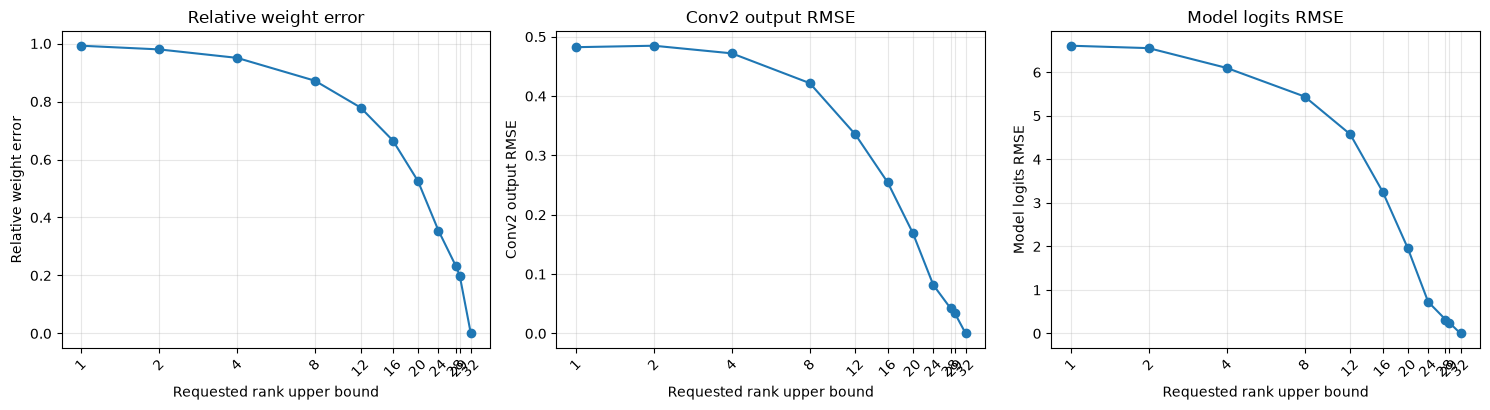

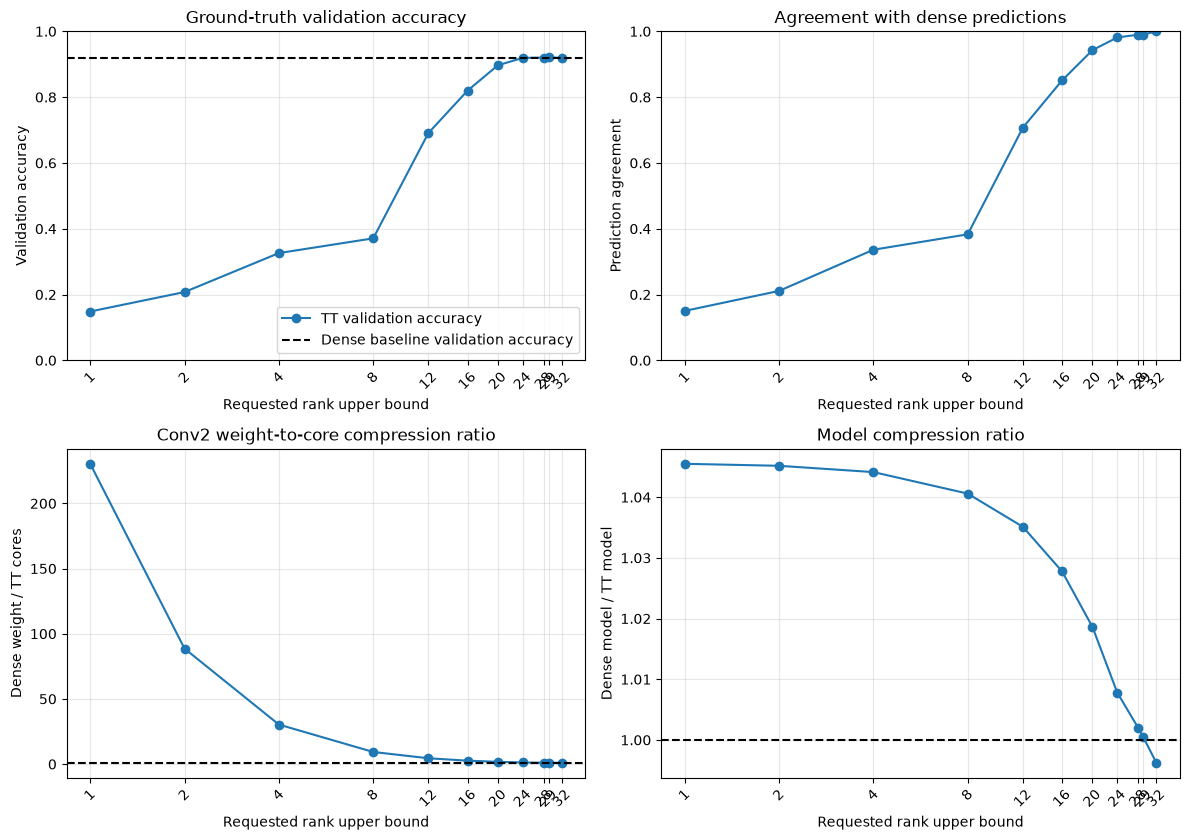

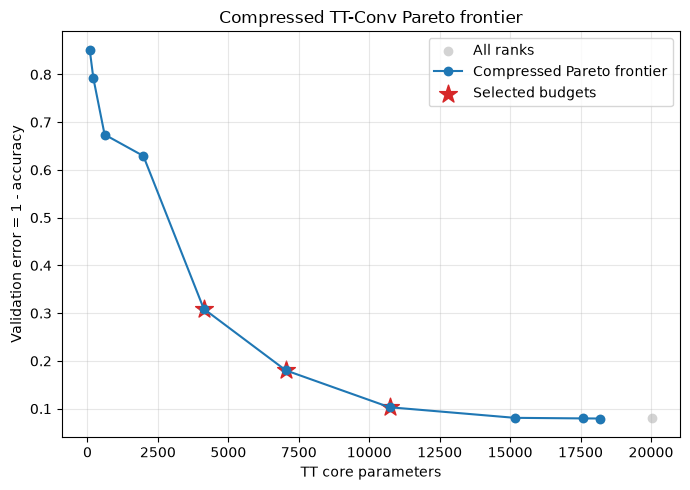

saved results to: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\20_fashion_mnist_cnn\03_pretrained_cnn_conv2_tt_rank_sweep


In [39]:
if "df_rank_sweep" not in globals():
    print("TODO 1完了後に可視化・保存を実行できます。")
else:
    plot_frame = df_rank_sweep.sort_values(
        "requested_rank_upper_bound"
    ).reset_index(drop=True)
    rank_values = plot_frame["requested_rank_upper_bound"]

    error_figure, error_axes = plt.subplots(1, 3, figsize=(15, 4.2))
    error_specs = [
        ("weight_relative_frobenius_error", "Relative weight error"),
        ("conv2_output_rmse", "Conv2 output RMSE"),
        ("logits_rmse", "Model logits RMSE"),
    ]
    for axis, (column, title) in zip(error_axes, error_specs):
        axis.plot(rank_values, plot_frame[column], marker="o")
        axis.set_xscale("log", base=2)
        axis.set_xticks(RANK_CANDIDATES)
        axis.set_xticklabels(RANK_CANDIDATES, rotation=45)
        axis.set_xlabel("Requested rank upper bound")
        axis.set_ylabel(title)
        axis.set_title(title)
        axis.grid(True, alpha=0.3)
    error_figure.tight_layout()

    tradeoff_figure, tradeoff_axes = plt.subplots(2, 2, figsize=(12, 8.5))
    accuracy_axis, agreement_axis, conv2_ratio_axis, model_ratio_axis = (
        tradeoff_axes.ravel()
    )

    accuracy_axis.plot(
        rank_values, plot_frame["validation_accuracy"],
        marker="o", label="TT validation accuracy"
    )
    accuracy_axis.axhline(
        dense_validation_accuracy, color="black", linestyle="--",
        label="Dense baseline validation accuracy"
    )
    accuracy_axis.set_ylim(0.0, 1.0)
    accuracy_axis.set_ylabel("Validation accuracy")
    accuracy_axis.set_title("Ground-truth validation accuracy")
    accuracy_axis.legend()

    agreement_axis.plot(
        rank_values, plot_frame["prediction_agreement"], marker="o"
    )
    agreement_axis.set_ylim(0.0, 1.0)
    agreement_axis.set_ylabel("Prediction agreement")
    agreement_axis.set_title("Agreement with dense predictions")

    conv2_ratio_axis.plot(
        rank_values,
        plot_frame["conv2_weight_to_core_compression_ratio"],
        marker="o",
    )
    conv2_ratio_axis.axhline(1.0, color="black", linestyle="--")
    conv2_ratio_axis.set_ylabel("Dense weight / TT cores")
    conv2_ratio_axis.set_title("Conv2 weight-to-core compression ratio")

    model_ratio_axis.plot(
        rank_values, plot_frame["model_compression_ratio"], marker="o"
    )
    model_ratio_axis.axhline(1.0, color="black", linestyle="--")
    model_ratio_axis.set_ylabel("Dense model / TT model")
    model_ratio_axis.set_title("Model compression ratio")

    for axis in tradeoff_axes.ravel():
        axis.set_xscale("log", base=2)
        axis.set_xticks(RANK_CANDIDATES)
        axis.set_xticklabels(RANK_CANDIDATES, rotation=45)
        axis.set_xlabel("Requested rank upper bound")
        axis.grid(True, alpha=0.3)
    tradeoff_figure.tight_layout()

    pareto_figure, pareto_axis = plt.subplots(figsize=(7, 5))
    pareto_axis.scatter(
        df_rank_sweep["tt_core_parameters"],
        1.0 - df_rank_sweep["validation_accuracy"],
        color="lightgray", label="All ranks"
    )
    if not df_pareto.empty:
        pareto_axis.plot(
            df_pareto["tt_core_parameters"],
            df_pareto["validation_error"],
            marker="o", label="Compressed Pareto frontier"
        )
    if not selected_rank_budget_candidates.empty:
        pareto_axis.scatter(
            selected_rank_budget_candidates["tt_core_parameters"],
            selected_rank_budget_candidates["validation_error"],
            marker="*", s=180, color="tab:red", label="Selected budgets"
        )
    pareto_axis.set_xlabel("TT core parameters")
    pareto_axis.set_ylabel("Validation error = 1 - accuracy")
    pareto_axis.set_title("Compressed TT-Conv Pareto frontier")
    pareto_axis.grid(True, alpha=0.3)
    pareto_axis.legend()
    pareto_figure.tight_layout()

    plt.show()

    if SAVE_RESULTS:
        results_dir.mkdir(parents=True, exist_ok=True)

        rank_sweep_to_save = df_rank_sweep.copy()
        rank_sweep_to_save["actual_ranks"] = (
            rank_sweep_to_save["actual_ranks"].map(str)
        )
        rank_sweep_to_save.to_csv(
            results_dir / "rank_sweep_results.csv", index=False
        )

        pareto_to_save = df_pareto.copy()
        pareto_to_save["actual_ranks"] = pareto_to_save["actual_ranks"].map(str)
        pareto_to_save.to_csv(
            results_dir / "pareto_frontier.csv", index=False
        )

        selected_to_save = selected_rank_budget_candidates.copy()
        if "actual_ranks" in selected_to_save.columns:
            selected_to_save["actual_ranks"] = (
                selected_to_save["actual_ranks"].map(str)
            )
        selected_to_save.to_csv(
            results_dir / "selected_rank_budget_candidates.csv", index=False
        )

        torch.save(
            {
                "train_indices": train_indices,
                "finetuning_monitor_indices": monitor_indices,
                "rank_validation_indices": rank_validation_indices,
            },
            results_dir / "split_indices.pt",
        )

        experiment_config = {
            "checkpoint_path": str(checkpoint_path.relative_to(project_root)),
            "checkpoint_best_epoch": checkpoint.get("best_epoch"),
            "checkpoint_best_validation_loss": checkpoint.get("best_validation_loss"),
            "seed": SEED,
            "split_lengths": list(SPLIT_LENGTHS),
            "validation_batch_size": VALIDATION_BATCH_SIZE,
            "out_modes": list(OUT_MODES),
            "in_modes": list(IN_MODES),
            "requested_rank_upper_bounds": RANK_CANDIDATES,
            "dtype": str(DTYPE),
            "device": str(DEVICE),
            "selection_status": selection_status,
            "selection_budget_column": "tt_core_parameters",
            "test_evaluated_in_notebook_03": False,
        }
        with (results_dir / "experiment_config.json").open(
            "w", encoding="utf-8"
        ) as file:
            json.dump(experiment_config, file, ensure_ascii=False, indent=2)

        error_figure.savefig(results_dir / "rank_errors.png", dpi=150)
        tradeoff_figure.savefig(results_dir / "rank_tradeoffs.png", dpi=150)
        pareto_figure.savefig(results_dir / "pareto_frontier.png", dpi=150)
        print("saved results to:", results_dir)

## 9. 次への接続

03で得た候補は、このtensorizationから得た**探索予算候補**です。04ではrequested rankをそのまま比較せず、選択された`tt_core_parameters`を予算として渡します。

各tensorizationについて整数の共通rank上限を探索し、予算以下で最大の表現規模を選びます。複数のrequested上限が同じactual ranksへ飽和する場合は、最小の上限を代表として記録します。目標予算、実際のparameter数、予算使用率を分けて保存します。

03は、固定tensorizationにおけるrank制限直後のtrade-offと、04へ渡す予算候補を整理した時点で終了します。